In [1]:
import io
import urllib.request
import zipfile
import pandas as pd
from IPython.display import display

UCI_ZIP_URL = "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip"
with urllib.request.urlopen(UCI_ZIP_URL, timeout=60) as response:
    zip_bytes = response.read()
with zipfile.ZipFile(io.BytesIO(zip_bytes)) as archive:
    hour_path = next(name for name in archive.namelist() if name.endswith("hour.csv"))
    bike = pd.read_csv(archive.open(hour_path))

bike["timestamp"] = pd.to_datetime(bike["dteday"]) + pd.to_timedelta(bike["hr"], unit="h")
print("Kích thước:", bike.shape)
print("Khoảng thời gian:", bike["timestamp"].min(), "→", bike["timestamp"].max())
print("\n8 dòng dữ liệu đầu:")
display(bike[["dteday", "hr", "season", "temp", "casual", "registered", "cnt"]].head(8))
print("\n8 dòng cuối:")
display(bike[["dteday", "hr", "season", "temp", "casual", "registered", "cnt"]].tail(8))

Kích thước: (17379, 18)
Khoảng thời gian: 2011-01-01 00:00:00 → 2012-12-31 23:00:00

8 dòng dữ liệu đầu:


,dteday,hr,season,temp,casual,registered,cnt
0,2011-01-01,0,1,0.24,3,13,16
1,2011-01-01,1,1,0.22,8,32,40
2,2011-01-01,2,1,0.22,5,27,32
3,2011-01-01,3,1,0.24,3,10,13
4,2011-01-01,4,1,0.24,0,1,1
5,2011-01-01,5,1,0.24,0,1,1
6,2011-01-01,6,1,0.22,2,0,2
7,2011-01-01,7,1,0.20,1,2,3



8 dòng cuối:


,dteday,hr,season,temp,casual,registered,cnt
17371,2012-12-31,16,1,0.26,30,184,214
17372,2012-12-31,17,1,0.26,14,150,164
17373,2012-12-31,18,1,0.26,10,112,122
17374,2012-12-31,19,1,0.26,11,108,119
17375,2012-12-31,20,1,0.26,8,81,89
17376,2012-12-31,21,1,0.26,7,83,90
17377,2012-12-31,22,1,0.26,13,48,61
17378,2012-12-31,23,1,0.26,12,37,49


Giá trị thiếu: 0
Dòng trùng theo instant: 0
instant có phải khóa tăng dần không: True

Tóm tắt cnt:
count    17379.0
mean       189.5
std        181.4
min          1.0
25%         40.0
50%        142.0
75%        281.0
max        977.0
Name: cnt, dtype: float64


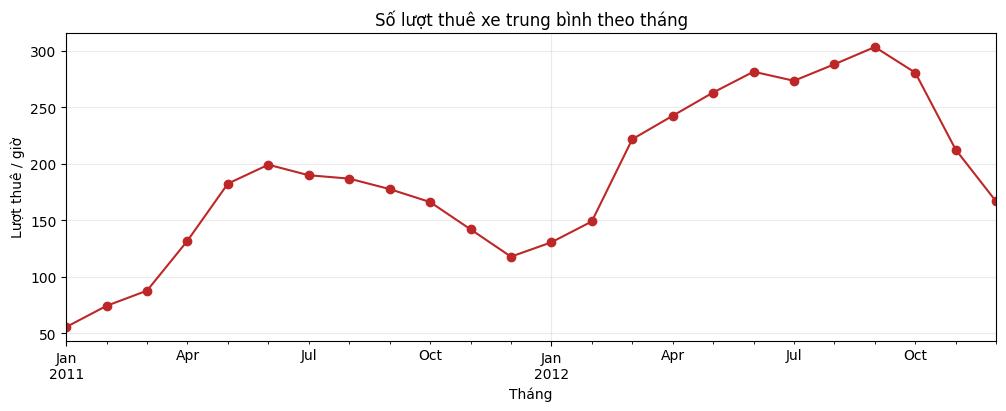

In [2]:
print("Giá trị thiếu:", int(bike.isna().sum().sum()))
print("Dòng trùng theo instant:", int(bike.duplicated(subset=["instant"]).sum()))
print("instant có phải khóa tăng dần không:", bike["instant"].is_unique and bike["instant"].is_monotonic_increasing)
# print("Tỷ lệ cnt = casual + registered:", round((bike["casual"] + bike["registered"]).eq(bike["cnt"]).mean(), 3))
print("\nTóm tắt cnt:")
print(bike["cnt"].describe().round(1))

monthly_mean = bike.set_index("timestamp")["cnt"].resample("MS").mean()
ax = monthly_mean.plot(figsize=(12, 4), marker="o", color="#BE2727")
ax.set_title("Số lượt thuê xe trung bình theo tháng")
ax.set_xlabel("Tháng")
ax.set_ylabel("Lượt thuê / giờ")
ax.grid(alpha=0.25)

Chiến lược: walk_forward


,Lần chia,Train rows,Test rows,Train start,Train end,Test start,Test end,Train mean cnt,Test mean cnt,MAE,RMSE,R2
0,Walk-forward 1,8645,1744,2011-01-01,2011-12-31,2012-01-01,2012-03-13,143.79,147.87,72.47,104.90,0.40
1,Walk-forward 2,10389,1750,2011-01-01,2012-03-13,2012-03-14,2012-05-25,144.48,250.20,71.43,101.04,0.77
2,Walk-forward 3,12139,1752,2011-01-01,2012-05-25,2012-05-26,2012-08-06,159.72,277.89,47.21,74.13,0.88
3,Walk-forward 4,13891,1752,2011-01-01,2012-08-06,2012-08-07,2012-10-18,174.62,293.52,42.04,67.16,0.92



Trung bình các lần walk-forward:


,MAE,RMSE,R2
mean,58.28,86.81,0.75
std,15.92,18.94,0.24


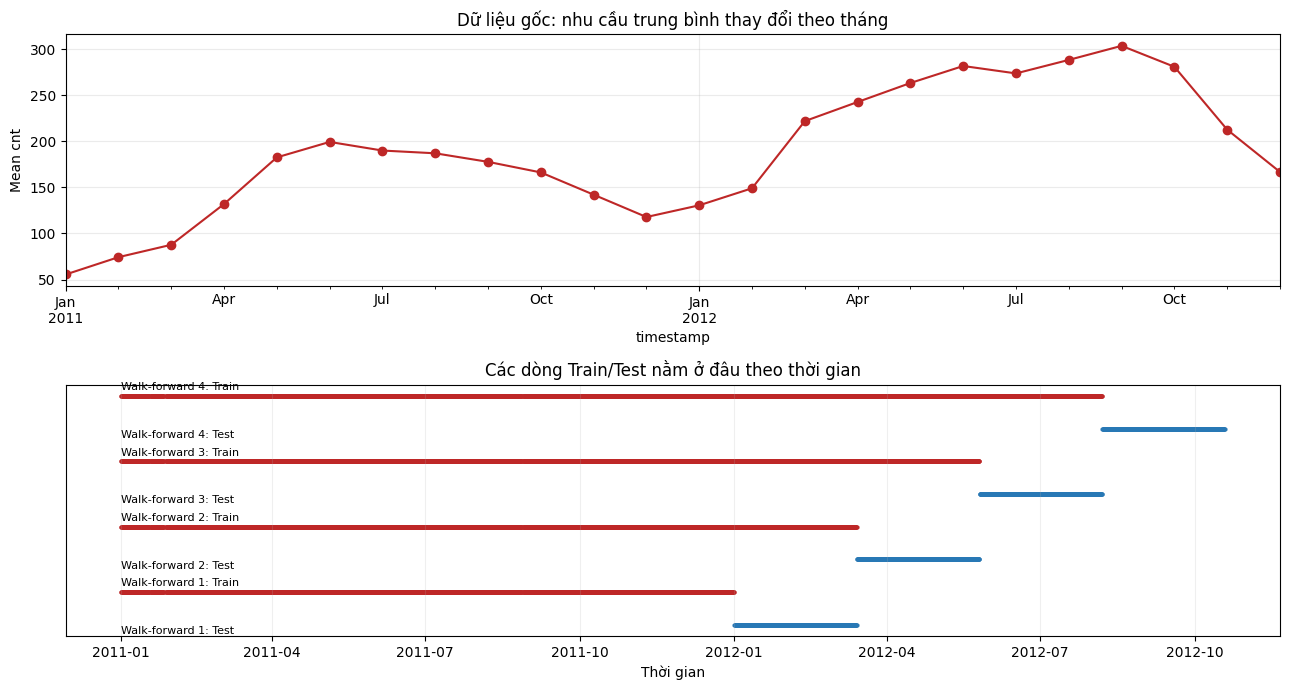

In [13]:
from sklearn.model_selection import train_test_split, GroupShuffleSplit, StratifiedGroupKFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

SPLIT_STRATEGY = "walk_forward"  # Chọn: random, stratified, group_by_day, stratified_group_by_day, time, walk_forward

# Dùng cùng bộ đặc trưng và cùng mô hình cho mọi chiến lược.
# casual/registered bị loại vì cnt = casual + registered; dùng chúng sẽ rò rỉ đáp án.
FEATURES = [
    "season", "yr", "mnth", "hr", "holiday", "weekday", "workingday",
    "weathersit", "temp", "atemp", "hum", "windspeed"
]
TARGET = "cnt"

def make_splits(data, strategy):
    if strategy == "random":
        train, test = train_test_split(data, test_size=0.20, random_state=42)
        return [(train.copy(), test.copy(), "Random split")]

    if strategy == "stratified":
        # Regression target liên tục: chia cnt thành 4 nhóm theo tứ phân vị chỉ để lấy mẫu.
        demand_band = pd.qcut(data[TARGET], q=4, labels=False, duplicates="drop")
        train_idx, test_idx = train_test_split(
            data.index.to_numpy(), test_size=0.20, random_state=42, stratify=demand_band
        )
        return [(data.loc[train_idx].copy(), data.loc[test_idx].copy(), "Stratified by demand band")]

    if strategy == "group_by_day":
        splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
        train_idx, test_idx = next(splitter.split(data, groups=data["dteday"]))
        return [(data.iloc[train_idx].copy(), data.iloc[test_idx].copy(), "Group split by day")]

    if strategy == "stratified_group_by_day":
        # Mỗi ngày là một group; demand bands giữ tương đối tỷ lệ mức nhu cầu.
        demand_band = pd.qcut(data[TARGET], q=4, labels=False, duplicates="drop")
        splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
        train_idx, test_idx = next(splitter.split(data, y=demand_band, groups=data["dteday"]))
        return [(data.iloc[train_idx].copy(), data.iloc[test_idx].copy(), "Stratified group by day")]

    ordered = data.sort_values("timestamp")
    if strategy == "time":
        dates = np.array(sorted(ordered["dteday"].unique()))
        cut = int(len(dates) * 0.80)
        train_dates, test_dates = dates[:cut], dates[cut:]
        train = ordered[ordered["dteday"].isin(train_dates)].copy()
        test = ordered[ordered["dteday"].isin(test_dates)].copy()
        return [(train, test, "Chronological holdout")]

    if strategy == "walk_forward":
        dates = np.array(sorted(data["dteday"].unique()))
        folds = []
        # 4 lần: mỗi lần học trên quá khứ dài hơn, kiểm tra trên khối ngày kế tiếp.
        for train_fraction in [0.50, 0.60, 0.70, 0.80]:
            train_end = int(len(dates) * train_fraction)
            test_end = int(len(dates) * (train_fraction + 0.10))
            train_dates = dates[:train_end]
            test_dates = dates[train_end:test_end]
            train = data[data["dteday"].isin(train_dates)].copy()
            test = data[data["dteday"].isin(test_dates)].copy()
            folds.append((train, test, f"Walk-forward {len(folds) + 1}"))
        return folds

    raise ValueError("SPLIT_STRATEGY không nằm trong danh sách lựa chọn")

splits = make_splits(bike, SPLIT_STRATEGY)
rows = []
for fold_number, (train, test, split_name) in enumerate(splits, start=1):
    model = RandomForestRegressor(
        n_estimators=60, max_depth=18, min_samples_leaf=2,
        random_state=42, n_jobs=-1
    )
    model.fit(train[FEATURES], train[TARGET])
    prediction = model.predict(test[FEATURES])
    rows.append({
        "Lần chia": split_name,
        "Train rows": len(train),
        "Test rows": len(test),
        "Train start": train["timestamp"].min().date(),
        "Train end": train["timestamp"].max().date(),
        "Test start": test["timestamp"].min().date(),
        "Test end": test["timestamp"].max().date(),
        "Train mean cnt": train[TARGET].mean(),
        "Test mean cnt": test[TARGET].mean(),
        "MAE": mean_absolute_error(test[TARGET], prediction),
        "RMSE": mean_squared_error(test[TARGET], prediction) ** 0.5,
        "R2": r2_score(test[TARGET], prediction),
    })

results = pd.DataFrame(rows)
print("Chiến lược:", SPLIT_STRATEGY)
display(results.round(2))
if SPLIT_STRATEGY == "walk_forward":
    print("\nTrung bình các lần walk-forward:")
    display(results[["MAE", "RMSE", "R2"]].agg(["mean", "std"]).round(2))

# Vẽ phân bố nhu cầu và vị trí các tập trên trục thời gian.
fig, axes = plt.subplots(2, 1, figsize=(13, 7))
monthly_mean = bike.set_index("timestamp")[TARGET].resample("MS").mean()
monthly_mean.plot(ax=axes[0], marker="o", color="#BE2727")
axes[0].set_title("Dữ liệu gốc: nhu cầu trung bình thay đổi theo tháng")
axes[0].set_ylabel("Mean cnt")
axes[0].grid(alpha=0.25)

for i, (train, test, split_name) in enumerate(splits):
    train_y = 2 * i + 1
    test_y = 2 * i
    axes[1].scatter(train["timestamp"], np.full(len(train), train_y), s=4, alpha=0.25, color="#BE2727")
    axes[1].scatter(test["timestamp"], np.full(len(test), test_y), s=4, alpha=0.25, color="#2878B5")
    axes[1].text(bike["timestamp"].min(), train_y + 0.18, f"{split_name}: Train", fontsize=8)
    axes[1].text(bike["timestamp"].min(), test_y - 0.28, f"{split_name}: Test", fontsize=8)
axes[1].set_title("Các dòng Train/Test nằm ở đâu theo thời gian")
axes[1].set_yticks([])
axes[1].set_xlabel("Thời gian")
axes[1].grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()


## 4. Ghi kết quả và chọn chiến lược

| Chiến lược | Ngày Train và Test có đan xen? | Test là tương lai của Train? | MAE | RMSE | Có phù hợp dự báo tương lai? Vì sao? |
|---|---|---|---|---|---|
| Random |Có |Không |25.22 |42.2 |Không phù hợp dự báo tương lai vì Train có thể chứa dữ liệu xảy ra sau các thời điểm trong Test|
| Stratified |Có |Không |25.5 |42.56 |Không phù hợp dự báo tương lai vì Train có thể chứa dữ liệu xảy ra sau các thời điểm trong Test|
| Group by day |Có |Không |26.52 |44.48 |Không, vì test chứa ngày cũ hơn Train nên đây ko phù hợp với mô hình dự đoán tương lai  |
| Stratified group by day |Có |Không |28.82 |50.41 |Không, vì test chứa ngày cũ hơn Train nên đây ko phù hợp với mô hình dự đoán tương lai |
| Time |Không |Có |44.83 |69.77 |Có, vì	train gồm giai đoạn trước, Test gồm giai đoạn sau, phù hợp với việc dùng quá khứ để dự báo tương lai. |
| Walk-forward |Không |Có |58.28 |86.81 |Có, vì	mỗi lần dùng dữ liệu quá khứ để dự báo giai đoạn kế tiếp. Lặp nhiều lần giúp đánh giá chất lượng dự báo qua các giai đoạn khác nhau. Nhưng sẽ tốn chi phí nhiều hơn time. |